# 03 · A GAN from scratch
Generator and discriminator MLPs on a ring of eight Gaussians, so mode coverage can be counted.

In [1]:
import sys, json
sys.path.insert(0, '..')
import torch
from gaf.common import device
dev = device(); print(torch.__version__, dev)

2.15.0 mps


In [2]:
from gaf.gan import train
r = train(seed=5, steps=1500, snapshots=(1500,))
for c in r['curve']: print(c)

{'step': 0, 'modes_covered': 0, 'high_quality_pct': 0.0}
{'step': 250, 'modes_covered': 0, 'high_quality_pct': 5.8}
{'step': 500, 'modes_covered': 3, 'high_quality_pct': 14.6}
{'step': 750, 'modes_covered': 6, 'high_quality_pct': 23.7}
{'step': 1000, 'modes_covered': 5, 'high_quality_pct': 28.9}
{'step': 1250, 'modes_covered': 5, 'high_quality_pct': 29.4}
{'step': 1500, 'modes_covered': 5, 'high_quality_pct': 37.1}


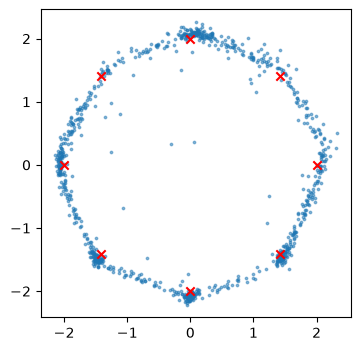

In [3]:
import matplotlib.pyplot as plt, numpy as np
from gaf.gan import MODES
p = np.array(r['snapshots'][1500])
plt.figure(figsize=(4, 4)); plt.scatter(p[:, 0], p[:, 1], s=3, alpha=0.5); plt.scatter(MODES[:, 0], MODES[:, 1], marker='x', c='r'); plt.axis('equal'); plt.show()

In [4]:
g = json.load(open('../results/gan.json'))
for run in g['runs']: print(run['loss'], run['seed'], run['final'])

non_saturating 0 {'step': 4000, 'modes_covered': 5, 'high_quality_pct': 75.1}
non_saturating 1 {'step': 4000, 'modes_covered': 4, 'high_quality_pct': 77.5}
non_saturating 2 {'step': 4000, 'modes_covered': 6, 'high_quality_pct': 76.0}
saturating 0 {'step': 4000, 'modes_covered': 6, 'high_quality_pct': 61.2}
saturating 1 {'step': 4000, 'modes_covered': 5, 'high_quality_pct': 53.6}
saturating 2 {'step': 4000, 'modes_covered': 5, 'high_quality_pct': 32.1}
